# Stroke Hospitalization Epidemiology in Georgia

- Data files are not included because they contain confidential patient-level information.
- The script is provided to demonstrate analytical workflow and methods.

# Required Libraries

In [1]:
library(tidyverse)
library(readxl)
library(gtsummary)
library(segmented)
library(splines)
library(nnet)
library(pscl)
library(caret)
library(pROC)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: MASS


Attaching package: 'MASS'


The following object is masked from 'package:gtsummary':

    select


The following object is masked from 'package:dplyr':

    select


Loading required package: nlme


Attaching package: 'nlme'


The following object is masked from 'package:dplyr':

    collapse


Classes and Methods for R originally developed in the
Political Science Computational Laboratory
Department of Political Science
Stanford Universit

# Import the Data

In [2]:
df <- excel_sheets("c:/Users/fpars/Documents/Data.xlsx") %>%
  set_names() %>%
  map_df(~ read_excel("c:/Users/fpars/Documents/Data.xlsx", sheet = .x), .id = "Year_Indicator")

Warning message:
"Expecting logical in O5242 / R5242C15: got 'I11.9'"
Warning message:
"Expecting logical in O8353 / R8353C15: got 'R57.0'"
Warning message:
"Expecting logical in O8354 / R8354C15: got 'J96.0'"
Warning message:
"Expecting logical in O8523 / R8523C15: got 'K76.0'"
Warning message:
"Expecting logical in O8688 / R8688C15: got 'I65.1'"
Warning message:
"Expecting logical in O8784 / R8784C15: got 'R40.2'"
Warning message:
"Expecting logical in O8814 / R8814C15: got 'R51'"
Warning message:
"Expecting logical in O8817 / R8817C15: got 'J96.0'"
Warning message:
"Expecting logical in O8828 / R8828C15: got 'I63.8'"
Warning message:
"Expecting logical in O8846 / R8846C15: got 'J96.0'"
Warning message:
"Expecting logical in O8904 / R8904C15: got 'J96.0'"
Warning message:
"Expecting logical in O8919 / R8919C15: got 'R40.0'"
Warning message:
"Expecting logical in O8920 / R8920C15: got 'I15.9'"
Warning message:
"Expecting logical in O8948 / R8948C15: got 'G93.6'"
Warning message:
"Expe

# Helper Functions

In [3]:
get_mode <- function(v) {
  uniqv <- unique(v[!is.na(v)])
  uniqv[which.max(tabulate(match(v, uniqv)))]
}

In [4]:
classify_stroke <- function(icd) {
  if (is.na(icd) || startsWith(icd, "I64")) return("Unspecified")
  if (startsWith(icd, "I63")) return("Ischemic")
  if (startsWith(icd, "I60") || startsWith(icd, "I61") || startsWith(icd, "I62")) return("Hemorrhagic")
  if (startsWith(icd, "G46")) return("Vascular Syndromes")
  return("Other Cerebrovascular")
}

In [5]:
categorize_age <- function(age) {
  if (is.na(age)) return(NA_character_)
  if (age < 45) return("<45")
  if (age >= 45 && age <= 64) return("45-64")
  if (age >= 65 && age <= 74) return("65-74")
  return(">=75")
}

In [6]:
categorize_los <- function(los) {
  if (is.na(los)) return(NA_character_)
  if (los < 3) return("<3")
  if (los >= 3 && los <= 7) return("3-7")
  if (los >= 8 && los <= 14) return("8-14")
  if (los >= 15 && los <= 30) return("15-30")
  return(">30")
}

# Data Cleaning

In [7]:
df$Stroke_Subtype <- vapply(df$Primary_Diagnosis_ICD10, classify_stroke, character(1))

In [8]:
df$Length_of_Hospital_Stay <- factor(
  sapply(df$Length_of_Stay, categorize_los),
  levels = c("<3", "3-7", "8-14", "15-30", ">30")
)

## Geographic Region Grouping

In [9]:
region_counts <- prop.table(table(df$Residential_Region))
small_regions <- names(region_counts[region_counts < 0.05])
df$Residential_Regions <- factor(ifelse(df$Residential_Region %in% small_regions, "Other", df$Residential_Region))

## Comorbidities

In [10]:
df$Comorbid_Condition_ICD10 <- as.character(df$Comorbid_Condition_ICD10)
df$Comorbid_Condition_ICD10[is.na(df$Comorbid_Condition_ICD10)] <- "None"

df$Hypertension <- if_else(
  grepl("^I1[0-5]", df$Comorbid_Condition_ICD10),
  "Yes", "No"
)

df$Atrial_Fibrillation <- if_else(
  grepl("^I48", df$Comorbid_Condition_ICD10),
  "Yes", "No"
)

df$Diabetes <- if_else(
  grepl("^E1[0-4]", df$Comorbid_Condition_ICD10),
  "Yes", "No"
)

df$Comorbidity_Group <- factor(case_when(
  df$Hypertension == "Yes" ~ "Hypertension",
  df$Atrial_Fibrillation == "Yes" ~ "Atrial Fibrillation",
  df$Diabetes == "Yes" ~ "Diabetes",
  TRUE ~ "Other/None"
))

## Complications

In [11]:
df$Primary_Diagnosis_Complication_ICD10 <- as.character(df$Primary_Diagnosis_Complication_ICD10)
df$Complication_Severity <- factor(case_when(
  is.na(df$Primary_Diagnosis_Complication_ICD10) ~ "None",
  grepl("^R40|^G93.6", df$Primary_Diagnosis_Complication_ICD10) ~ "Severe Neurological",
  grepl("^J96|^J18|^I46", df$Primary_Diagnosis_Complication_ICD10) ~ "Systemic Medical",
  TRUE ~ "Other Mild Complication"
))

## Procedural Pathway

In [12]:
intervention_cols <- c("Intervention_1_NCSP", "Intervention_2_NCSP", "Intervention_3_NCSP")
for (col in intervention_cols) {
  df[[col]] <- coalesce(as.character(df[[col]]), "")
}
combined_codes <- paste(df$Intervention_1_NCSP, df$Intervention_2_NCSP, df$Intervention_3_NCSP)

df$Procedural_Pathway <- factor(case_when(
  grepl("WAA|AAS", combined_codes) ~ "Surgical/Endovascular Intervention",
  grepl("ZYZ", combined_codes)     ~ "Advanced Imaging Only",
  TRUE                             ~ "Conservative Management"
))

## Clean Factors

In [13]:
categorical_vars <- c("Sex", "Residential_Regions", "Case_Type", 
                      "Admission_Type", "Length_of_Hospital_Stay", "Comorbidity_Group", 
                      "Complication_Severity", "Procedural_Pathway")

for (var in categorical_vars) {
  df[[var]] <- as.factor(trimws(as.character(df[[var]])))
}

df$Primary_Diagnosis_Complication_ICD10 <- NULL

## Set Reference Levels

In [14]:
df$Sex                      <- relevel(df$Sex, ref = "Female")
df$Residential_Regions      <- relevel(df$Residential_Regions, ref = "Other")
df$Case_Type                <- relevel(df$Case_Type, ref = names(which.max(table(df$Case_Type))))
df$Admission_Type           <- relevel(df$Admission_Type, ref = "Emergency Service")
df$Length_of_Hospital_Stay  <- relevel(df$Length_of_Hospital_Stay, ref = "<3")
df$Comorbidity_Group        <- relevel(df$Comorbidity_Group, ref = "Other/None")
df$Complication_Severity    <- relevel(df$Complication_Severity, ref = "None")
df$Procedural_Pathway       <- relevel(df$Procedural_Pathway, ref = "Conservative Management")

## Missing Observations

In [15]:
df_original <- df
df$Age[is.na(df$Age)] <- median(df$Age, na.rm = TRUE)
df$Sex[is.na(df$Sex)] <- get_mode(df$Sex)
df$Residential_Region[is.na(df$Residential_Region)] <- get_mode(df$Residential_Region)
df$Residential_Regions[is.na(df$Residential_Regions)] <- get_mode(df$Residential_Regions)
df$Case_Type[is.na(df$Case_Type)] <- get_mode(df$Case_Type)
df$Admission_Type[is.na(df$Admission_Type)] <- get_mode(df$Admission_Type)
df$Residence_Type[is.na(df$Residence_Type)] <- get_mode(df$Residence_Type)

# Data Inspection

In [16]:
glimpse(df)

Rows: 150,000
Columns: 28
$ Year_Indicator           <chr> "2014", "2014", "2014", "2014", "2014", "2014…
$ Region_Organization      <chr> "Kakheti", "Kakheti", "Imereti", "Tbilisi", "…
$ Age                      <dbl> 78, 63, 58, 82, 58, 68, 54, 76, 77, 75, 65, 9…
$ Sex                      <fct> Female, Male, Female, Female, Female, Female,…
$ Residential_Region       <chr> "Kakheti", "Kakheti", "Samegrelo-Zemo Svaneti…
$ Residence_Type           <chr> "Rural", "Rural", "Urban", "Urban", "Urban", …
$ Date                     <dttm> 2014-01-01, 2014-01-01, 2014-01-01, 2014-01-…
$ Length_of_Stay           <dbl> 1, 2, 1, 6, 2, 5, 2, 4, 5, 4, 5, 15, 13, 6, 3…
$ Admission_Type           <fct> Self-Referred, Self-Referred, Self-Referred, …
$ Case_Type                <fct> Emergency, Emergency, Emergency, Emergency, E…
$ Hospitalization_Outcome  <chr> "Transferred to Another Hospital", "Died", "T…
$ Primary_Diagnosis_ICD10  <chr> "G46.8", "I61.3", "I61.5", "I63.5", "I63.5", …
$ Manifestatio

# Frequency Table

In [17]:
freq_table <- df %>%
  dplyr::select(
    Stroke_Subtype,
    Age,
    Sex,
    Residential_Regions,
    Case_Type,
    Admission_Type,
    Length_of_Stay,
    Comorbidity_Group,
    Complication_Severity,
    Procedural_Pathway,
    Hospitalization_Outcome
  ) %>%
  tbl_summary(
    by = Stroke_Subtype,
    missing = "no",
    type = list(
      Age ~ "continuous",
      Length_of_Stay ~ "continuous"
    ),
    statistic = list(
      all_continuous() ~ "{median} ({p25}, {p75})",
      all_categorical() ~ "{n} ({p}%)"
    ),
    digits = list(
      all_continuous() ~ 1,
      all_categorical() ~ c(0, 1)
    ),
    label = list(
      Age ~ "Age (years)",
      Sex ~ "Sex",
      Residential_Regions ~ "Geographic Region",
      Case_Type ~ "Case Type",
      Admission_Type ~ "Admission Type",
      Length_of_Stay ~ "Length of Hospital Stay (days)",
      Comorbidity_Group ~ "Comorbidity Category",
      Complication_Severity ~ "Complication Severity",
      Procedural_Pathway ~ "Procedural Pathway",
      Hospitalization_Outcome ~ "In-Hospital Outcome"
    )
  ) %>%
  add_overall(last = FALSE) %>%
  add_p(
    test = list(
      all_continuous() ~ "kruskal.test",
      all_categorical() ~ "chisq.test"
    )
  ) %>%
  bold_labels() %>%
  as_tibble() %>%
  mutate(across(everything(), ~ str_squish(as.character(.x))))

freq_table

# write.csv(freq_table, "Table_Frequency.csv", row.names = FALSE)

**Characteristic**,"**Overall** N = 150,000","**Hemorrhagic** N = 23,452","**Ischemic** N = 67,609","**Unspecified** N = 4,388","**Vascular Syndromes** N = 54,551",**p-value**
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
__Age (years)__,"70.0 (61.0, 79.0)","65.0 (56.0, 75.0)","73.0 (64.0, 80.0)","72.0 (62.0, 79.0)","69.0 (61.0, 78.0)",<0.001
__Sex__,NA,NA,NA,NA,NA,<0.001
Female,"74,016 (49.3%)","9,825 (41.9%)","33,248 (49.2%)","2,127 (48.5%)","28,816 (52.8%)",NA
Male,"75,984 (50.7%)","13,627 (58.1%)","34,361 (50.8%)","2,261 (51.5%)","25,735 (47.2%)",NA
__Geographic Region__,NA,NA,NA,NA,NA,<0.001
Other,"18,898 (12.6%)","3,094 (13.2%)","8,477 (12.5%)",671 (15.3%),"6,656 (12.2%)",NA
Adjara,"12,818 (8.5%)","1,427 (6.1%)","4,185 (6.2%)",340 (7.7%),"6,866 (12.6%)",NA
Imereti,"26,351 (17.6%)","3,139 (13.4%)","11,874 (17.6%)",920 (21.0%),"10,418 (19.1%)",NA
Kakheti,"13,305 (8.9%)","2,431 (10.4%)","5,653 (8.4%)",727 (16.6%),"4,494 (8.2%)",NA


## Segmented Regression

In [18]:
population_geo <- read_excel("c:/Users/fpars/Documents/Population.xlsx", sheet = 1) %>%
  filter(`regions, self-governed units` == "Georgia") %>%
  dplyr::select(`2014`:`2023`) %>%
  pivot_longer(everything(), names_to = "Year", values_to = "Population_thousands") %>%
  mutate(
    Year = as.numeric(Year),
    Population = as.numeric(gsub(",", "", Population_thousands)) * 1000
  ) %>%
  dplyr::select(Year, Population)

annual_overall <- df %>%
  mutate(Year = as.numeric(as.character(Year_Indicator))) %>%
  filter(between(Year, 2014, 2023)) %>%
  count(Year, name = "Hospitalizations") %>%
  left_join(population_geo, by = "Year") %>%
  mutate(Rate = Hospitalizations / Population * 100000)

model <- lm(log(Rate) ~ Year, data = annual_overall)
seg_model <- segmented(model, seg.Z = ~Year, npsi = 1)

bp <- seg_model$psi[1, "Est."]
sl <- slope(seg_model)$Year

calc_apc <- function(est, se = NULL) {
  tibble(
    APC = (exp(est) - 1) * 100,
    Lower = if (is.null(se)) NA_real_ else (exp(est - 1.96 * se) - 1) * 100,
    Upper = if (is.null(se)) NA_real_ else (exp(est + 1.96 * se) - 1) * 100,
    P = if (is.null(se)) NA_real_ else 2 * pnorm(abs(est / se), lower.tail = FALSE)
  )
}

apc1 <- calc_apc(sl[1, "Est."], sl[1, "St.Err."])
apc2 <- calc_apc(sl[2, "Est."], sl[2, "St.Err."])

w1 <- bp - 2014
w2 <- 2023 - bp

aapc_log <- (w1 * sl[1, "Est."] + w2 * sl[2, "Est."]) / 9
aapc <- calc_apc(aapc_log)

trend_statistics <- tibble(
  Joinpoint = round(bp),
  APC_before = apc1$APC,
  APC_before_lower = apc1$Lower,
  APC_before_upper = apc1$Upper,
  APC_before_p = apc1$P,
  APC_after = apc2$APC,
  APC_after_lower = apc2$Lower,
  APC_after_upper = apc2$Upper,
  APC_after_p = apc2$P,
  AAPC = aapc$APC
)

fitted <- tibble(Year = 2014:2023) %>%
  mutate(Rate = exp(predict(seg_model, newdata = .)))

Joinpoint,APC_before,APC_before_lower,APC_before_upper,APC_before_p,APC_after,APC_after_lower,APC_after_upper,APC_after_p,AAPC
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2019,5.870133,0.1637099,11.90166,0.04360542,-5.104604,-10.21949,0.3016781,0.06381879,0.8005518


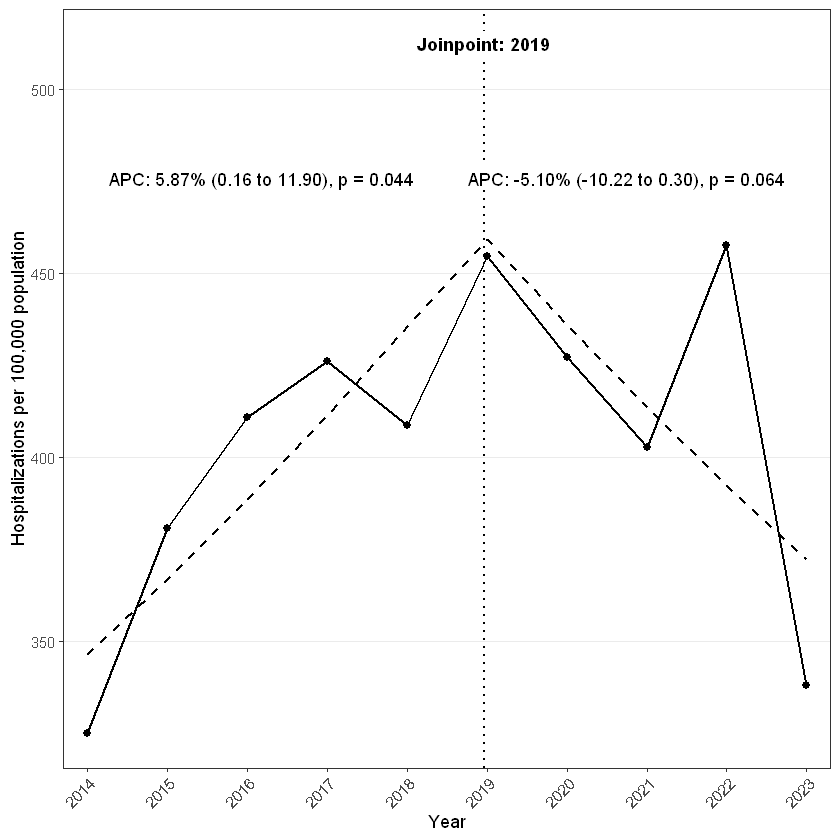

In [19]:
p <- ggplot(annual_overall, aes(Year, Rate)) +
  geom_line(linewidth = 0.8) +
  geom_point(size = 2) +
  geom_line(
    data = fitted,
    aes(y = Rate),
    linetype = "dashed",
    linewidth = 0.8
  ) +
  geom_vline(
    xintercept = bp,
    linetype = "dotted",
    linewidth = 0.7
  ) +
  annotate(
    "label",
    x = bp,
    y = max(annual_overall$Rate) * 1.12,
    label = paste0("Joinpoint: ", round(bp)),
    fontface = "bold",
    linewidth = 0
  ) +
  annotate(
    "label",
    x = 2014.2,
    y = max(annual_overall$Rate) * 1.04,
    label = sprintf(
      "APC: %.2f%% (%.2f to %.2f), p = %.3f",
      apc1$APC, apc1$Lower, apc1$Upper, apc1$P
    ),
    hjust = 0,
    linewidth = 0
  ) +
  annotate(
    "label",
    x = 2022.8,
    y = max(annual_overall$Rate) * 1.04,
    label = sprintf(
      "APC: %.2f%% (%.2f to %.2f), p = %.3f",
      apc2$APC, apc2$Lower, apc2$Upper, apc2$P
    ),
    hjust = 1,
    linewidth = 0
  ) +
  scale_x_continuous(
    breaks = 2014:2023,
    limits = c(2013.7, 2023.3),
    expand = c(0, 0)
  ) +
  labs(
    x = "Year",
    y = "Hospitalizations per 100,000 population"
  ) +
  theme_bw(base_size = 11) +
  theme(
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

trend_statistics

p

# ggsave("Figure_Trend.svg", p, width = 7, height = 5, units = "in")

# ggsave("Figure_Trend.tiff", p, width = 7, height = 5, units = "in", dpi = 300, compression = "lzw")

## Regression Model

In [20]:
df_model <- df %>%
  filter(Stroke_Subtype %in% c("Ischemic", "Hemorrhagic", "Unspecified")) %>%
  mutate(
    Stroke_Subtype = factor(
      Stroke_Subtype,
      levels = c("Ischemic", "Hemorrhagic", "Unspecified")
    ),
    Sex = relevel(factor(Sex), ref = "Female"),
    Residential_Region = relevel(factor(Residential_Regions), ref = "Other"),
    Case_Type = relevel(factor(Case_Type), ref = "Emergency"),
    Admission_Type = relevel(factor(Admission_Type), ref = "Self-Referred"),
    Hypertension = factor(Hypertension),
    Atrial_Fibrillation = factor(Atrial_Fibrillation),
    Diabetes = factor(Diabetes)
  )

model_ns5 <- multinom(
  Stroke_Subtype ~
    ns(Age, df = 5) +
    Sex +
    Residential_Regions +
    Case_Type +
    Admission_Type +
    Hypertension +
    Atrial_Fibrillation +
    Diabetes,
  data = df_model,
  trace = FALSE
)

summary(model_ns5)

Call:
multinom(formula = Stroke_Subtype ~ ns(Age, df = 5) + Sex + Residential_Regions + 
    Case_Type + Admission_Type + Hypertension + Atrial_Fibrillation + 
    Diabetes, data = df_model, trace = FALSE)

Coefficients:
            (Intercept) ns(Age, df = 5)1 ns(Age, df = 5)2 ns(Age, df = 5)3
Hemorrhagic   0.9710731        -2.036578      -2.20451552       -2.6483717
Unspecified  -2.2456039        -0.287786       0.05585339       -0.9011401
            ns(Age, df = 5)4 ns(Age, df = 5)5     SexMale
Hemorrhagic       -3.2266659        -2.487138  0.01671507
Unspecified        0.7535208         0.353738 -0.06373309
            Residential_RegionsAdjara Residential_RegionsImereti
Hemorrhagic               -0.11474891                -0.31988180
Unspecified               -0.01671146                -0.04708863
            Residential_RegionsKakheti Residential_RegionsKvemo Kartli
Hemorrhagic                  0.1860606                     0.032699865
Unspecified                  0.4893937     

In [21]:
coef_mat <- summary(model_ns5)$coefficients
se_mat <- summary(model_ns5)$standard.errors

Table_Model <- map_dfr(
  rownames(coef_mat),
  function(outcome) {
    tibble(
      Outcome = outcome,
      Term = colnames(coef_mat),
      Estimate = coef_mat[outcome, ],
      SE = se_mat[outcome, ]
    )
  }
) %>%
  filter(!str_detect(Term, "^ns\\(Age")) %>%
  mutate(
    RRR = exp(Estimate),
    CI_lower = exp(Estimate - 1.96 * SE),
    CI_upper = exp(Estimate + 1.96 * SE),
    P_value = 2 * pnorm(
      abs(Estimate / SE),
      lower.tail = FALSE
    ),
    Term = recode(
      Term,
      `(Intercept)` = "Intercept",
      SexMale = "Sex: Male",
      HypertensionYes = "Hypertension",
      Atrial_FibrillationYes = "Atrial fibrillation",
      DiabetesYes = "Diabetes"
    )
  )

Table_Model

# write_csv(Table_Model, "Table_Model.csv")

Outcome,Term,Estimate,SE,RRR,CI_lower,CI_upper,P_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Hemorrhagic,Intercept,0.971073077,0.14966359,2.6407767,1.96940693,3.5410161,8.676862e-11
Hemorrhagic,Sex: Male,0.016715067,0.01643360,1.0168555,0.98462464,1.0501415,3.090927e-01
Hemorrhagic,Residential_RegionsAdjara,-0.114748908,0.03847200,0.8915900,0.82683176,0.9614201,2.857553e-03
Hemorrhagic,Residential_RegionsImereti,-0.319881798,0.02997125,0.7262349,0.68480206,0.7701745,1.362250e-26
Hemorrhagic,Residential_RegionsKakheti,0.186060638,0.03319647,1.2044953,1.12861991,1.2854717,2.084561e-08
Hemorrhagic,Residential_RegionsKvemo Kartli,0.032699865,0.03430387,1.0332404,0.96605384,1.1050996,3.404678e-01
Hemorrhagic,Residential_RegionsSamegrelo-Zemo Svaneti,0.081222601,0.03381512,1.0846123,1.01505719,1.1589336,1.630746e-02
Hemorrhagic,Residential_RegionsShida Kartli,-0.326848495,0.03516810,0.7211930,0.67315614,0.7726578,1.487478e-20
Hemorrhagic,Residential_RegionsTbilisi,-0.038389260,0.02599655,0.9623383,0.91453229,1.0126432,1.397545e-01


## Forest Plot

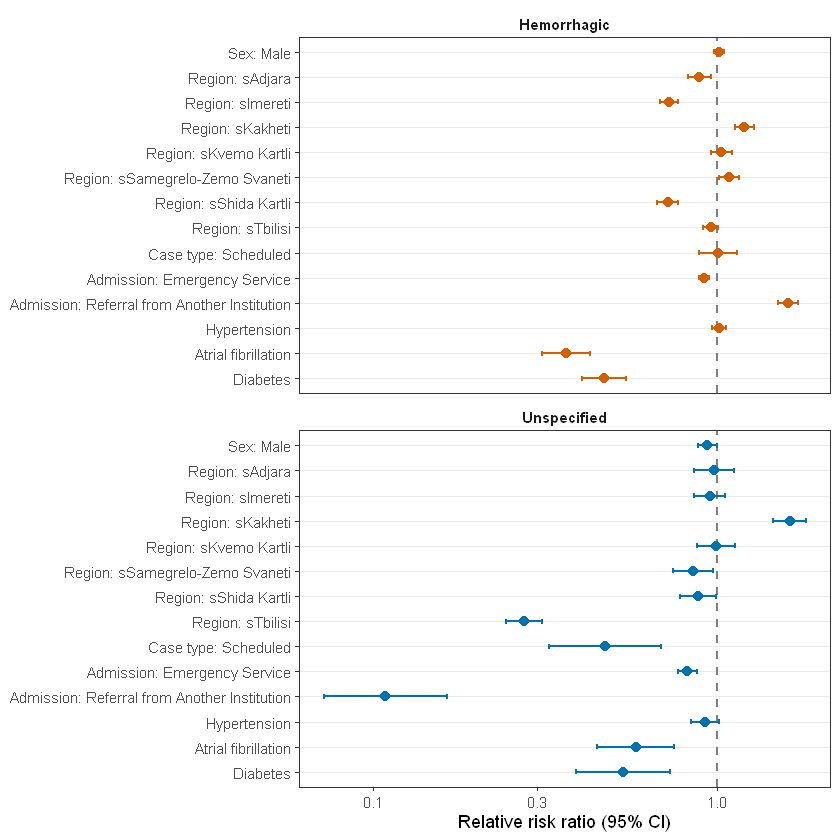

In [22]:
forest_data <- Table_Model %>%
  filter(Term != "Intercept") %>%
  mutate(
    Term = recode(
      Term,
      "SexMale" = "Male sex",
      "HypertensionYes" = "Hypertension",
      "Atrial_FibrillationYes" = "Atrial fibrillation",
      "DiabetesYes" = "Diabetes"
    ),
    Term = str_replace(Term, "^Residential_Region", "Region: "),
    Term = str_replace(Term, "^Case_Type", "Case type: "),
    Term = str_replace(Term, "^Admission_Type", "Admission: "),
    Term = str_replace_all(Term, "_", " "),
    Term = factor(Term, levels = rev(unique(Term))),
    Outcome = factor(
      Outcome,
      levels = c("Hemorrhagic", "Unspecified")
    )
  )

forest_plot <- ggplot(
  forest_data,
  aes(
    x = Term,
    y = RRR,
    ymin = CI_lower,
    ymax = CI_upper,
    color = Outcome
  )
) +
  geom_hline(
    yintercept = 1,
    linetype = "dashed",
    linewidth = 0.6,
    color = "grey50"
  ) +
  geom_errorbar(
    width = 0.2,
    linewidth = 0.6
  ) +
  geom_point(size = 2.5) +
  facet_wrap(
    ~ Outcome,
    ncol = 1,
    scales = "free_y"
  ) +
  scale_color_manual(
    values = c(
      "Hemorrhagic" = "#D55E00",
      "Unspecified" = "#0072B2"
    )
  ) +
  scale_y_log10() +
  coord_flip() +
  labs(
    x = NULL,
    y = "Relative risk ratio (95% CI)"
  ) +
  theme_bw(base_size = 11) +
  theme(
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    strip.background = element_blank(),
    strip.text = element_text(face = "bold"),
    legend.position = "none"
  )

forest_plot

# ggsave("Figure_Forest_Plot.svg", forest_plot, width = 7, height = 7, units = "in", device = "svg")

# ggsave("Figure_Forest_Plot.tiff", forest_plot, width = 7, height = 7, units = "in", dpi = 300, compression = "lzw")

# Model Evaluation

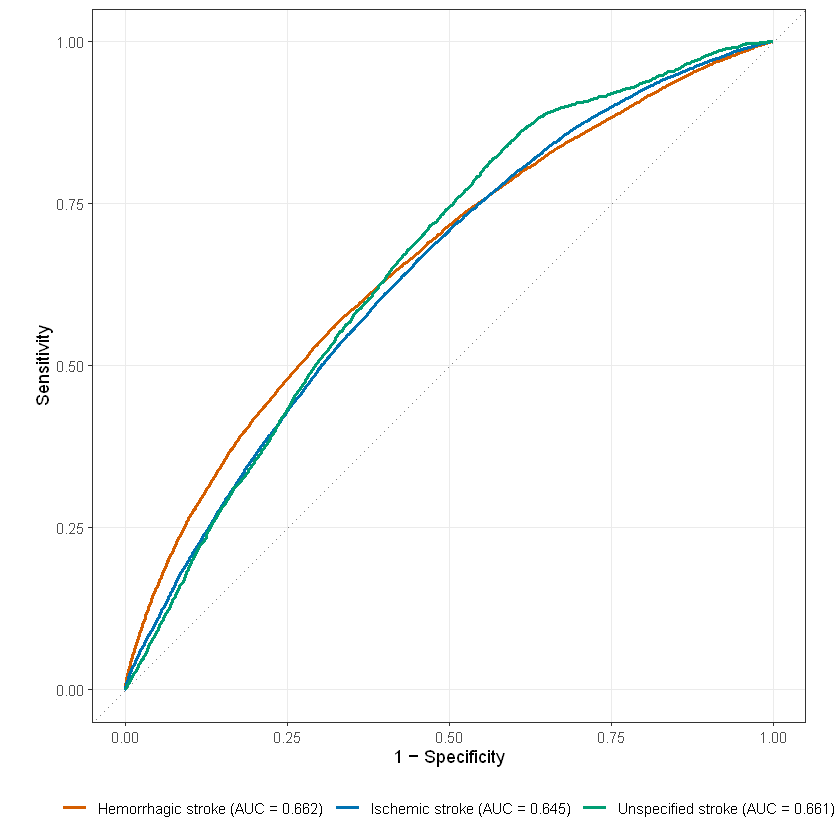

In [23]:
observed <- df_model$Stroke_Subtype
probabilities <- predict(model_ns5, newdata = df_model, type = "probs")

classes <- c("Ischemic", "Hemorrhagic", "Unspecified")

roc_data <- map_dfr(classes, function(cls) {
  r <- roc(
    response = as.numeric(observed == cls),
    predictor = probabilities[, cls],
    quiet = TRUE
  )
  
  tibble(
    Outcome = cls,
    Specificity = r$specificities,
    Sensitivity = r$sensitivities,
    AUC = as.numeric(auc(r))
  )
})

auc_labels <- roc_data %>%
  distinct(Outcome, AUC) %>%
  mutate(
    Label = paste0(
      recode(
        Outcome,
        Ischemic = "Ischemic stroke",
        Hemorrhagic = "Hemorrhagic stroke",
        Unspecified = "Unspecified stroke"
      ),
      " (AUC = ", sprintf("%.3f", AUC), ")"
    )
  ) %>%
  {setNames(.$Label, .$Outcome)}

auc_plot <- ggplot(
  roc_data,
  aes(
    x = 1 - Specificity,
    y = Sensitivity,
    color = Outcome
  )
) +
  geom_line(linewidth = 0.9) +
  geom_abline(
    intercept = 0,
    slope = 1,
    linetype = "dotted",
    color = "grey50"
  ) +
  scale_color_manual(
    values = c(
      Ischemic = "#0072B2",
      Hemorrhagic = "#D55E00",
      Unspecified = "#009E73"
    ),
    labels = auc_labels
  ) +
  coord_equal() +
  labs(
    x = "1 − Specificity",
    y = "Sensitivity",
    color = NULL
  ) +
  theme_bw(base_size = 11) +
  theme(
    panel.grid.minor = element_blank(),
    legend.position = "bottom"
  )

auc_plot

# ggsave("Figure_AUC.svg", auc_plot, width = 7, height = 6, units = "in", device = "svg")

# ggsave("Figure_AUC.tiff", auc_plot, width = 7, height = 6, units = "in", dpi = 300, compression = "lzw")

In [24]:
null_model <- multinom(
  Stroke_Subtype ~ 1,
  data = df_model,
  trace = FALSE
)

LR_stat <- 2 * (logLik(model_ns5) - logLik(null_model))
df_LR <- attr(logLik(model_ns5), "df") - attr(logLik(null_model), "df")
p_LR <- pchisq(LR_stat, df = df_LR, lower.tail = FALSE)

pR2_values <- pR2(model_ns5)[c("McFadden", "r2ML", "r2CU")]

pred_class <- predict(model_ns5, newdata = df_model, type = "class")
conf_mat <- confusionMatrix(pred_class, df_model$Stroke_Subtype)

performance <- data.frame(
  Class = rownames(conf_mat$byClass),
  Sensitivity = conf_mat$byClass[, "Sensitivity"],
  Specificity = conf_mat$byClass[, "Specificity"],
  PPV = conf_mat$byClass[, "Pos Pred Value"],
  NPV = conf_mat$byClass[, "Neg Pred Value"],
  Balanced_Accuracy = conf_mat$byClass[, "Balanced Accuracy"]
)

model_metrics <- data.frame(
  Metric = c(
    "Likelihood-ratio χ²",
    "df",
    "LR test p-value",
    "McFadden R²",
    "Cox-Snell R²",
    "Nagelkerke R²",
    "AIC",
    "BIC",
    "Apparent accuracy",
    "Kappa"
  ),
  Value = c(
    as.numeric(LR_stat),
    df_LR,
    p_LR,
    pR2_values["McFadden"],
    pR2_values["r2ML"],
    pR2_values["r2CU"],
    AIC(model_ns5),
    BIC(model_ns5),
    conf_mat$overall["Accuracy"],
    conf_mat$overall["Kappa"]
  )
)

model_metrics
performance
conf_mat$table

fitting null model for pseudo-r2


Metric,Value
<chr>,<dbl>
Likelihood-ratio χ²,7.613602e+03
df,3.800000e+01
LR test p-value,0.000000e+00
McFadden R²,5.458021e-02
Cox-Snell R²,7.666778e-02
Nagelkerke R²,9.981485e-02
AIC,1.319602e+05
BIC,1.323389e+05
Apparent accuracy,7.136272e-01


,Class,Sensitivity,Specificity,PPV,NPV,Balanced_Accuracy
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Class: Ischemic,Class: Ischemic,0.9727551,0.08976293,0.7218576,0.5756738,0.5312590
Class: Hemorrhagic,Class: Hemorrhagic,0.1001194,0.97231829,0.5408892,0.7683628,0.5362188
Class: Unspecified,Class: Unspecified,0.0000000,1.00000000,NaN,0.9540278,0.5000000


             Reference
Prediction    Ischemic Hemorrhagic Unspecified
  Ischemic       65767       21104        4237
  Hemorrhagic     1842        2348         151
  Unspecified        0           0           0

# Model Justification

In [25]:
m_linear <- multinom(
  Stroke_Subtype ~ Age + Sex + Residential_Regions +
    Case_Type + Admission_Type +
    Hypertension + Atrial_Fibrillation + Diabetes,
  data = df_model, trace = FALSE
)

m_ns3 <- multinom(
  Stroke_Subtype ~ ns(Age, df = 3) + Sex + Residential_Regions +
    Case_Type + Admission_Type +
    Hypertension + Atrial_Fibrillation + Diabetes,
  data = df_model, trace = FALSE
)

m_ns4 <- multinom(
  Stroke_Subtype ~ ns(Age, df = 4) + Sex + Residential_Regions +
    Case_Type + Admission_Type +
    Hypertension + Atrial_Fibrillation + Diabetes,
  data = df_model, trace = FALSE
)

m_ns5 <- multinom(
  Stroke_Subtype ~ ns(Age, df = 5) + Sex + Residential_Regions +
    Case_Type + Admission_Type +
    Hypertension + Atrial_Fibrillation + Diabetes,
  data = df_model, trace = FALSE
)

model_comparison <- data.frame(
  Model = c("Linear age", "Natural spline df = 3",
            "Natural spline df = 4", "Natural spline df = 5"),
  AIC = c(AIC(m_linear), AIC(m_ns3), AIC(m_ns4), AIC(m_ns5)),
  BIC = c(BIC(m_linear), BIC(m_ns3), BIC(m_ns4), BIC(m_ns5)),
  LogLik = c(
    as.numeric(logLik(m_linear)),
    as.numeric(logLik(m_ns3)),
    as.numeric(logLik(m_ns4)),
    as.numeric(logLik(m_ns5))
  )
)

model_comparison
anova(m_linear, m_ns3, m_ns4, m_ns5, test = "Chisq")

Model,AIC,BIC,LogLik
<chr>,<dbl>,<dbl>,<dbl>
Linear age,132035.5,132338.5,-65985.77
Natural spline df = 3,131994.9,132335.7,-65961.47
Natural spline df = 4,131981.6,132341.4,-65952.82
Natural spline df = 5,131960.2,132338.9,-65940.11


Model,Resid. df,Resid. Dev,Test,Df,LR stat.,Pr(Chi)
<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
Age + Sex + Residential_Regions + Case_Type + Admission_Type + Hypertension + Atrial_Fibrillation + Diabetes,190866,131971.5,,NA,NA,NA
"ns(Age, df = 3) + Sex + Residential_Regions + Case_Type + Admission_Type + Hypertension + Atrial_Fibrillation + Diabetes",190862,131922.9,1 vs 2,4,48.59212,7.102435e-10
"ns(Age, df = 4) + Sex + Residential_Regions + Case_Type + Admission_Type + Hypertension + Atrial_Fibrillation + Diabetes",190860,131905.6,2 vs 3,2,17.29542,1.755286e-04
"ns(Age, df = 5) + Sex + Residential_Regions + Case_Type + Admission_Type + Hypertension + Atrial_Fibrillation + Diabetes",190858,131880.2,3 vs 4,2,25.42747,3.009510e-06


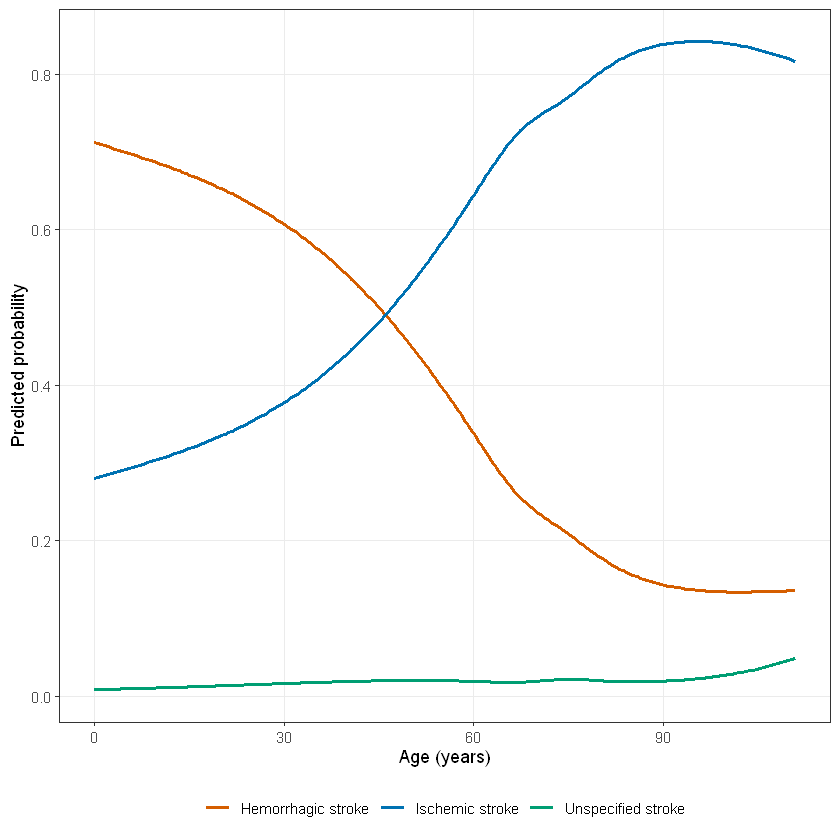

In [26]:
newdat <- data.frame(
  Age = seq(
    min(df_model$Age, na.rm = TRUE),
    max(df_model$Age, na.rm = TRUE),
    length.out = 200
  ),
  Sex = "Female",
  Residential_Regions = "Tbilisi",
  Case_Type = "Emergency",
  Admission_Type = "Self-Referred",
  Hypertension = "No",
  Atrial_Fibrillation = "No",
  Diabetes = "No"
)

pred <- predict(model_ns5, newdata = newdat, type = "probs")

plot_data <- bind_cols(
  newdat["Age"],
  as.data.frame(pred)
) %>%
  pivot_longer(
    -Age,
    names_to = "Stroke_Subtype",
    values_to = "Probability"
  )

p <- ggplot(
  plot_data,
  aes(Age, Probability, color = Stroke_Subtype)
) +
  geom_line(linewidth = 0.9) +
  scale_color_manual(
    values = c(
      Ischemic = "#0072B2",
      Hemorrhagic = "#D55E00",
      Unspecified = "#009E73"
    ),
    labels = c(
      Ischemic = "Ischemic stroke",
      Hemorrhagic = "Hemorrhagic stroke",
      Unspecified = "Unspecified stroke"
    )
  ) +
  labs(
    x = "Age (years)",
    y = "Predicted probability",
    color = NULL
  ) +
  theme_bw(base_size = 11) +
  theme(
    panel.grid.minor = element_blank(),
    legend.position = "bottom"
  )

p

# ggsave("Figure_Model_Justification.svg", p, width = 7, height = 6, units = "in", device = "svg")

# ggsave("Figure_Model_Justification.tiff", p, width = 7, height = 6, units = "in", dpi = 300, compression = "lzw")

# Complete-Case Sensitivity Analysis

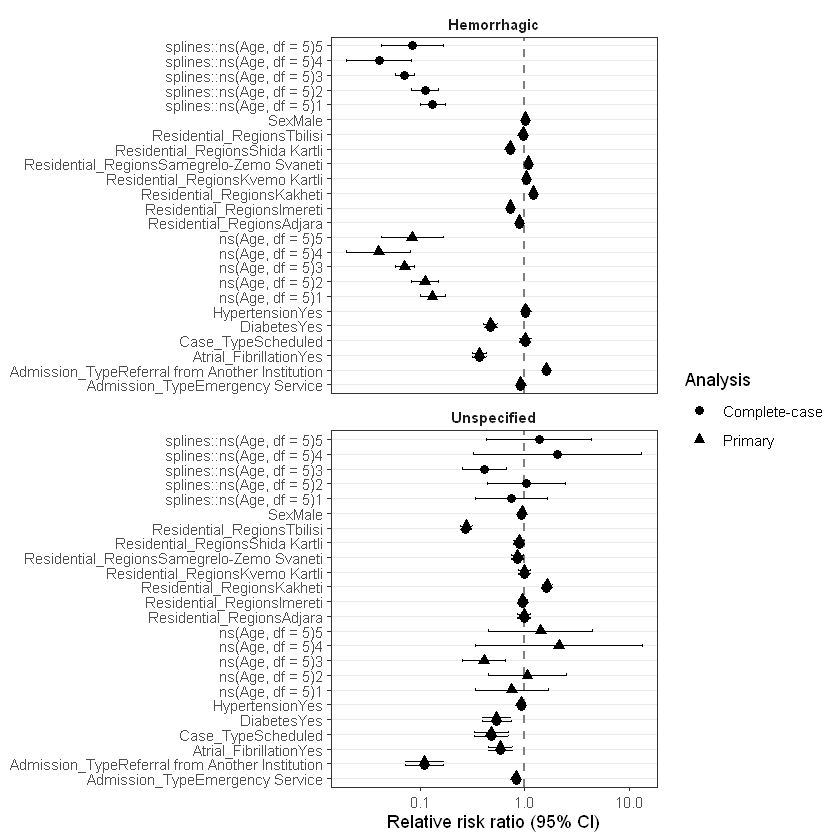

In [27]:
df_cc <- df_original %>%
  filter(Stroke_Subtype %in% c("Ischemic", "Hemorrhagic", "Unspecified")) %>%
  mutate(
    Stroke_Subtype = factor(
      Stroke_Subtype,
      levels = c("Ischemic", "Hemorrhagic", "Unspecified")
    ),
    Sex = relevel(factor(Sex), ref = "Female"),
    Residential_Regions = relevel(
      factor(Residential_Regions), ref = "Other"
    ),
    Case_Type = relevel(factor(Case_Type), ref = "Emergency"),
    Admission_Type = relevel(factor(Admission_Type), ref = "Self-Referred"),
    Hypertension = factor(Hypertension),
    Atrial_Fibrillation = factor(Atrial_Fibrillation),
    Diabetes = factor(Diabetes)
  ) %>%
  tidyr::drop_na(
    Age, Sex, Residential_Regions, Case_Type,
    Admission_Type, Hypertension, Atrial_Fibrillation, Diabetes
  )

model_cc <- nnet::multinom(
  Stroke_Subtype ~
    splines::ns(Age, df = 5) +
    Sex +
    Residential_Regions +
    Case_Type +
    Admission_Type +
    Hypertension +
    Atrial_Fibrillation +
    Diabetes,
  data = df_cc,
  trace = FALSE
)

extract_rrr <- function(model, analysis_name) {
  
  coefs <- summary(model)$coefficients
  ses   <- summary(model)$standard.errors
  
  map_dfr(rownames(coefs), function(outcome) {
    
    tibble(
      Outcome = outcome,
      Term = colnames(coefs),
      Estimate = coefs[outcome, ],
      SE = ses[outcome, ]
    )
  }) %>%
    mutate(
      RRR = exp(Estimate),
      CI_lower = exp(Estimate - 1.96 * SE),
      CI_upper = exp(Estimate + 1.96 * SE),
      Analysis = analysis_name
    )
}

primary_rrr <- extract_rrr(model_ns5, "Primary")
cc_rrr      <- extract_rrr(model_cc, "Complete-case")

sensitivity_data <- bind_rows(primary_rrr, cc_rrr) %>%
  filter(Term != "(Intercept)")

sensitivity_plot <- ggplot(
  sensitivity_data,
  aes(
    x = Term,
    y = RRR,
    ymin = CI_lower,
    ymax = CI_upper,
    shape = Analysis
  )
) +
  geom_hline(
    yintercept = 1,
    linetype = "dashed",
    linewidth = 0.6,
    color = "grey50"
  ) +
  geom_errorbar(
    position = position_dodge(width = 0.5),
    width = 0.2
  ) +
  geom_point(
    position = position_dodge(width = 0.5),
    size = 2.3
  ) +
  facet_wrap(
    ~ Outcome,
    ncol = 1,
    scales = "free_y"
  ) +
  scale_y_log10() +
  coord_flip() +
  labs(
    x = NULL,
    y = "Relative risk ratio (95% CI)",
    shape = "Analysis"
  ) +
  theme_bw(base_size = 11) +
  theme(
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    strip.background = element_blank(),
    strip.text = element_text(face = "bold")
  )

sensitivity_plot